### SPAM EMAIL DETECTION USING TENSORFLOW, NLP AND LSTM

In [4]:
import re
import string
import warnings # This library handles warning messages generated by Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk  # Natural Language Toolkit.
import tensorflow as tf # ML and DL 

# nltk.corpus: Contains language resources and text collections.
from nltk.corpus import stopwords # For stopwords

# Tokenizer converts words into numerical representations.
from tensorflow.keras.preprocessing.text import Tokenizer

# pad_sequences makes all input sequences have the same length.
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Stops model training when performance stops improving.
# Reduces the learning rate when model performance stops improving.
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

warnings.filterwarnings("ignore") # This tells Python to ignore warning messages.

### STEP 1: CONFIGURATION

In [5]:
CSV_FILE = "Emails.csv"

MAX_WORDS = 20000
MAX_LEN = 100
EMBEDDING_DIM = 32
LSTM_UNITS = 16
BATCH_SIZE = 32
EPOCHS = 20
RANDOM_STATE = 42

MODEL_FILE = "spam_email_model.keras"

np.random.seed(RANDOM_STATE) # This sets the random seed for NumPy.
tf.random.set_seed(RANDOM_STATE) # This sets the random seed for TensorFlow.

### STEP 2: DOWNLOAD STOPWORDS

In [6]:
nltk.download("stopwords", quiet=True)

# Retrieves English stopwords and stores them in a set.
STOP_WORDS = set(stopwords.words("english"))

# Preserve negation words because they can change meaning.
STOP_WORDS -= {"no", "nor", "not", "never"}

### STEP 3: LOAD DATASET

In [7]:
print("\nLoading dataset...")

data = pd.read_csv(CSV_FILE) # Reads actual csv file 

print("\nDataset shape:", data.shape) 
print("\nAvailable columns:")

# Returns the names of all columns in the DataFrame, converts the column index into a normal Python list.
print(data.columns.tolist())

# Identify common text and label column names.
text_candidates = [
    "text", "email", "message", "content", "body"
]

label_candidates = [
    "label", "category", "spam", "class", "type"
]

column_map = {
    str(column).strip().lower(): column
    for column in data.columns
}

text_column = next(
    (
        column_map[name]
        for name in text_candidates
        if name in column_map
    ),
    None
)

label_column = next(
    (
        column_map[name]
        for name in label_candidates
        if name in column_map
    ),
    None
)

if text_column is None or label_column is None:
    raise ValueError(
        "Could not identify the email text and label columns. "
        "Inspect data.columns and update the column configuration."
    )

data = data[[text_column, label_column]].copy() # Select only the required columns

data.columns = ["text", "label"] # Rename the columns

data = data.dropna(subset=["text", "label"]) # Remove missing values

data["text"] = data["text"].astype(str).str.strip() # Convert email text into strings

data = data[data["text"] != ""] # Remove empty email messages

print("\nFirst five records:")
print(data.head())


Loading dataset...

Dataset shape: (5728, 2)

Available columns:
['text', 'spam']

First five records:
                                                text  label
0  Subject: naturally irresistible your corporate...      1
1  Subject: the stock trading gunslinger  fanny i...      1
2  Subject: unbelievable new homes made easy  im ...      1
3  Subject: 4 color printing special  request add...      1
4  Subject: do not have money , get software cds ...      1


### STEP 4: NORMALIZE LABELS

In [8]:
def normalize_label(value):
    """
    Convert common spam/ham labels to:
    spam = 1
    ham  = 0
    """

    value = str(value).strip().lower()

    if value in {"spam", "1", "true", "junk"}:
        return 1

    if value in {"ham", "0", "false", "not spam", "non-spam"}:
        return 0

    return np.nan


data["label"] = data["label"].apply(normalize_label)

data = data.dropna(subset=["label"])

data["label"] = data["label"].astype(int)

if data["label"].nunique() != 2:
    raise ValueError(
        "The dataset must contain both spam and ham labels."
    )

# Remove exact duplicate records.
data = data.drop_duplicates(
    subset=["text", "label"]
).reset_index(drop=True)

print("\nCleaned dataset shape:", data.shape)

print("\nLabel distribution:")
print(data["label"].value_counts().rename({
    0: "Ham",
    1: "Spam"
}))


Cleaned dataset shape: (5695, 2)

Label distribution:
label
Ham     4327
Spam    1368
Name: count, dtype: int64


### STEP 5: VISUALIZE LABEL DISTRIBUTION

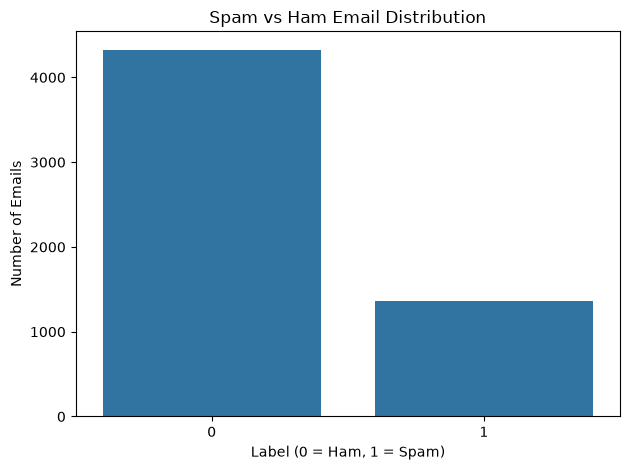

In [9]:
sns.countplot(data=data, x="label")

plt.title("Spam vs Ham Email Distribution")
plt.xlabel("Label (0 = Ham, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

### STEP 6: SPLIT DATA BEFORE PREPROCESSING

In [10]:
X = data["text"]
y = data["label"]

# Keep the test set separate from training and validation.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 4556
Validation samples: 569
Testing samples: 570


### STEP 7: TEXT PREPROCESSING

In [11]:
def clean_text(text):
    """
    Clean email text using the same procedure
    for training, validation, testing and prediction.
    """

    text = str(text).lower() # Lowercase

    # Remove a Subject prefix only when it appears
    # at the beginning of the message.
    text = re.sub(
        r"^\s*subject\s*:\s*",
        "",
        text,
        count=1
    )

    # Remove punctuation.
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Keep words and remove selected stopwords.
    words = text.split()

    words = [
        word for word in words
        if word not in STOP_WORDS
    ]

    return " ".join(words)


print("\nCleaning email text...")

X_train_clean = X_train.apply(clean_text)
X_val_clean = X_val.apply(clean_text)
X_test_clean = X_test.apply(clean_text)


Cleaning email text...


### STEP 8: TOKENIZATION

In [12]:
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>" # Out of Vocabulary
)

# Fit the tokenizer only on training data.
tokenizer.fit_on_texts(X_train_clean)

train_sequences = tokenizer.texts_to_sequences(
    X_train_clean
)

val_sequences = tokenizer.texts_to_sequences(
    X_val_clean
)

test_sequences = tokenizer.texts_to_sequences(
    X_test_clean
)

### STEP 9: PADDING

In [13]:
train_padded = pad_sequences(
    train_sequences, # Tokenized training emails.
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

val_padded = pad_sequences(
    val_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

test_padded = pad_sequences(
    test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
    # Dictionary containing words and their assigned numbers.
)

print("\nVocabulary size:", vocab_size)
print("Training input shape:", train_padded.shape)


Vocabulary size: 20000
Training input shape: (4556, 100)


### STEP 10: CONVERT LABELS TO NUMPY ARRAYS

In [14]:
# Converts testing labels into a NumPy array of float32.
y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

### STEP 11: BUILD LSTM MODEL

In [15]:
# Creates a neural network model. Sequential means layers are arranged one after another.

model = tf.keras.Sequential([

    # Defines the shape of the input.
    # MAX_LEN represents the maximum number of tokens in each email.
    tf.keras.layers.Input(shape=(MAX_LEN,)),

    # This layer converts integer word IDs into meaningful numerical vectors.
    tf.keras.layers.Embedding(
        input_dim=vocab_size, # Total vocabulary size considered by the model
        output_dim=EMBEDDING_DIM, # Number of values in each word's vector
        mask_zero=True # Tells the model to ignore padding zeros
    ),

    tf.keras.layers.LSTM(LSTM_UNITS), # LSTM Layer

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ), # Dense layer

    # Dropout helps prevent overfitting
    tf.keras.layers.Dropout(0.3),
    # 0.3 means 30% of the relevant neurons are randomly switched off during each training update.

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )

    # This is the final layer. Dense(1) means one output neuron. Sigmoid converts the output into a value between 0 and 1.
])

### STEP 12: COMPILE MODEL

In [16]:
model.compile(
    optimizer="adam", # Adam is an optimization algorithm.
    loss="binary_crossentropy", # Loss measures how wrong the model's predictions are. 0 = Ham, 1 = Spam
    metrics=["accuracy"] # the percentage of correct predictions.
)

print("\nModel architecture:")
model.summary()


Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 32)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 643,713 (2.46 MB)

 Trainable params: 643,713 (2.46 MB)

 Non-trainable params: 0 (0.00 B)

### STEP 13: CALLBACKS

In [17]:
early_stopping = EarlyStopping(
    monitor="val_loss", # Watches validation loss
    patience=3, # Waits 3 epochs without improvement before stopping
    restore_best_weights=True # Restores weights from the epoch with the best validation loss
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", # Watches validation loss
    factor=0.5, # Reduces learning rate to half
    patience=2, # Waits 2 epochs without improvement
    min_lr=0.00001 # Minimum learning rate allowed
)

### STEP 14: TRAIN MODEL

In [18]:
print("\nTraining model...")

history = model.fit(
    train_padded, # Contains training emails converted into padded numerical sequences.
    y_train, # Contains the correct labels of training emails.
    validation_data=(val_padded, y_val), # val_padded contains validation emails,  y_val contains their correct labels.
    epochs=EPOCHS, # One epoch means one complete pass through the training dataset.
    batch_size=BATCH_SIZE, # Batch size determines how many training examples are processed together before the model updates its weights.
    callbacks=[early_stopping, reduce_lr],
    verbose=1 # Displays training progress in the output.
)


Training model...
Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.8694 - loss: 0.3248 - val_accuracy: 0.9772 - val_loss: 0.0864 - learning_rate: 0.0010
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9873 - loss: 0.0456 - val_accuracy: 0.9772 - val_loss: 0.0777 - learning_rate: 0.0010
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9965 - loss: 0.0184 - val_accuracy: 0.9807 - val_loss: 0.0624 - learning_rate: 0.0010
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9985 - loss: 0.0085 - val_accuracy: 0.9895 - val_loss: 0.0409 - learning_rate: 0.0010
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9998 - loss: 0.0030 - val_accuracy: 0.9895 - val_loss: 0.0428 - learning_rate: 0.0010
Epoch 6/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.9912 - val_loss: 0.0406 - learning_rate: 0.0010
Epoch 7/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy

### STEP 15: EVALUATE MODEL

In [19]:
print("\nEvaluating model on unseen test data...")

test_loss, test_accuracy = model.evaluate(
    test_padded, # Padded test email sequences
    y_test, # Actual test labels
    verbose=0 # Hides the detailed progress output
)

print(f"\nTest Loss: {test_loss:.4f}") # 	Model's test loss
print(f"Test Accuracy: {test_accuracy:.4f}") # Model's test accuracy
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")


Evaluating model on unseen test data...

Test Loss: 0.0655
Test Accuracy: 0.9877
Test Accuracy Percentage: 98.77%


### STEP 16: CLASSIFICATION REPORT

In [20]:
test_probabilities = model.predict(
    test_padded, # Contains the preprocessed and padded test messages.
    verbose=0 # Hides the progress bar while making predictions.
).ravel() # Converts the prediction result into a one-dimensional array.

test_predictions = (
    test_probabilities >= 0.5 # Checks whether probability is greater than or equal to 0.5.
).astype(int) # Converts Boolean values into integers . True becomes 1 (Spam), False becomes 0 (Ham).

print("\nClassification Report:\n")

print(
    classification_report(
        y_test.astype(int), # Actual test labels converted into integers 
        test_predictions, # Labels predicted by the model
        labels=[0, 1], # 	Specifies the two classes
        target_names=["Ham", "Spam"], # Gives readable names to classes
        zero_division=0 # 	Returns 0 instead of a warning when a metric has a zero denominator
    ) 
)

print(
    "Accuracy:",
    accuracy_score(
        y_test.astype(int), # Actual Answer
        test_predictions # Model Prediction
    )
)


Classification Report:

              precision    recall  f1-score   support

         Ham       1.00      0.99      0.99       433
        Spam       0.96      0.99      0.97       137

    accuracy                           0.99       570
   macro avg       0.98      0.99      0.98       570
weighted avg       0.99      0.99      0.99       570

Accuracy: 0.987719298245614


### STEP 17: CONFUSION MATRIX

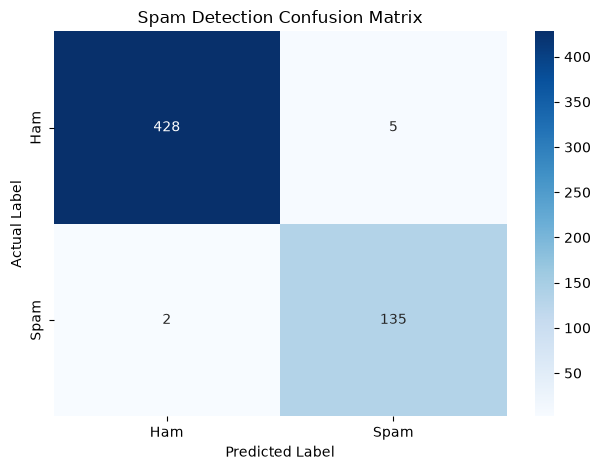

In [21]:
cm = confusion_matrix ( # Compares actual labels with predicted labels.
    y_test.astype(int), # Actual test result
    test_predictions, # Predicted result
    labels=[0, 1]) # 0 for Ham , 1 for spam

sns.heatmap( # Creates a heatmap using Seaborn.
    cm, # Data displayed in the heatmap.
    annot=True, # Displays numerical values inside each cell.
    fmt="d", # Displays values as integers.
    cmap="Blues", # Uses a blue colour scheme.
    xticklabels=["Ham", "Spam"], # Names for predicted labels.
    yticklabels=["Ham", "Spam"] # Names for actual labels.
)

plt.title("Spam Detection Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### STEP 18: PLOT TRAINING ACCURACY

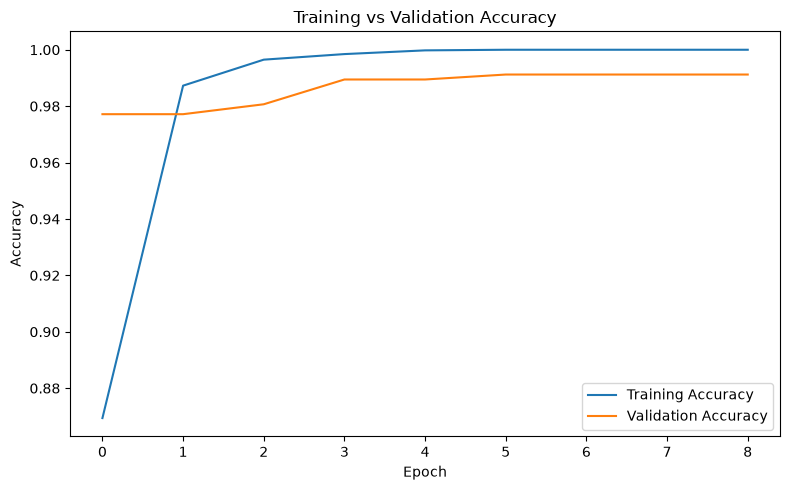

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"], # Retrieves training accuracy for each epoch.
    label="Training Accuracy" # 
)

plt.plot(
    history.history["val_accuracy"], # Retrieves validation accuracy for each epoch.
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

### STEP 19: PLOT TRAINING LOSS


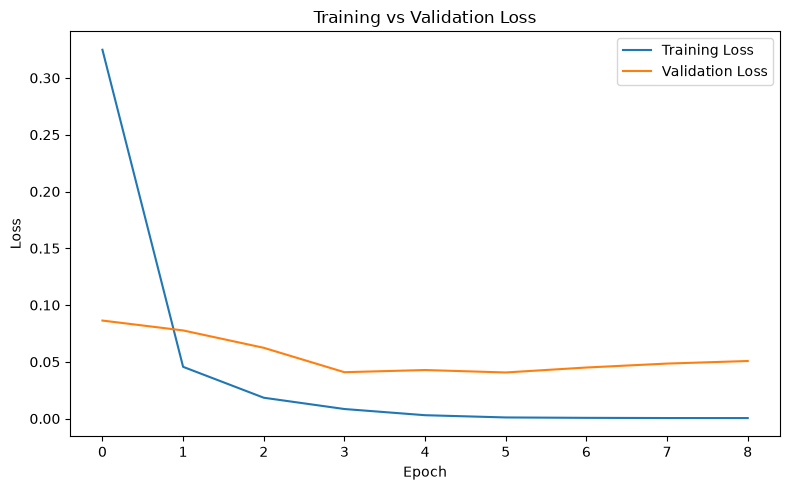

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"], # Retrieves training loss values for each epoch.
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"], # Retrieves validation loss values for each epoch.
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

###  STEP 20: SAVE TRAINED MODEL AND TOKENIZER

In [24]:
import json
import pickle # Imports the Pickle library to save Python objects such as the tokenizer.

model.save(MODEL_FILE) # Saves the complete trained model.

with open("spam_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file) 

# Saves the Python object into the file. The tokenizer used to convert words into numerical sequences.

with open("spam_config.json", "w") as file:
    json.dump({ # Writes Python data into a JSON file.
        "max_len": MAX_LEN,
        "threshold": 0.5
    }, file, indent=4) # Formats the JSON file with four-space indentation for readability.

print("\nModel saved as:", MODEL_FILE)
print("Tokenizer saved as: spam_tokenizer.pkl")
print("Configuration saved as: spam_config.json")


Model saved as: spam_email_model.keras
Tokenizer saved as: spam_tokenizer.pkl
Configuration saved as: spam_config.json


### STEP 21: PREDICT A NEW EMAIL

In [25]:
def predict_email(email):
    """
    Predict whether a new email is spam or ham.
    """

    # Clean the email
    cleaned_email = clean_text(email)

    # Convert email into numerical sequences
    sequence = tokenizer.texts_to_sequences(
        [cleaned_email]
    )

    # Apply padding
    padded_email = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict Spam probability
    probability = float(
        model.predict(
            padded_email,
            verbose=0
        )[0][0]
    )

    if probability >= 0.5:
        prediction = "SPAM"
    else:
        prediction = "HAM (NOT SPAM)"

    print("\nEmail:")
    print(email)

    print("\nPrediction:", prediction)

    print(
        f"Estimated spam probability: {probability:.2%}"
    )

    return prediction, probability

### STEP 22: TEST EXAMPLE EMAILS

In [26]:
predict_email(
    "Congratulations! You have won a free prize. "
    "Click here to claim your reward now!"
)

predict_email(
    "Hello, please send me the project report "
    "before tomorrow's meeting."
)


Email:
Congratulations! You have won a free prize. Click here to claim your reward now!

Prediction: SPAM
Estimated spam probability: 93.62%

Email:
Hello, please send me the project report before tomorrow's meeting.

Prediction: HAM (NOT SPAM)
Estimated spam probability: 0.45%


('HAM (NOT SPAM)', 0.004470410291105509)

### STEP 23: INTERACTIVE EMAIL PREDICTION

In [1]:
while True:

    user_email = input(
        "\nEnter an email to classify "
        "(or type 'exit' to quit): "
    )

    if user_email.strip().lower() == "exit":
        print("Spam detection program closed.")
        break

    if not user_email.strip():
        print("Please enter a valid email message.")
        continue

    predict_email(user_email)

Spam detection program closed.
